# Phân Tích Thực Nghiệm Giải Đấu Connect Four AI (Nhóm 13)
**Đề tài**: Xây dựng và đánh giá Game AI đa cấp độ
**GVHD**: Thầy Đỗ Như Tài
**Thành viên**: Bùi Minh Trung (NT), Trần Lê Minh Tâm, Chương Gia Thịnh, Nguyễn Thành Tài

In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Thiết lập thư mục gốc
ROOT_DIR = Path("..").resolve()
RESULTS_DIR = ROOT_DIR / "results"
TABLES_DIR = RESULTS_DIR / "tables"
LOGS_DIR = RESULTS_DIR / "logs"
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Results directory:", RESULTS_DIR)

Results directory: C:\Users\taith\ConnectFour_7X6_AdvanceAi_ThayTai_Nhom13\results


## 1. Phân Tích Ablation A1: Hiệu Quả Cắt Tỉa Alpha-Beta & Thứ Tự Nước Đi
So sánh số nút duyệt (Nodes) và thời gian thực thi (Time ms) ở các độ sâu khi bật/tắt cắt tỉa $\alpha$-$\beta$ và sắp xếp thứ tự duyệt Center-First.

,Depth,Config,Pruning,Ordering,Nodes,Time_ms,Best_Move,Score_Value
0,4,Pruning_ON_Ordering_ON,True,True,78,2.011,4,0
1,4,Pruning_ON_Ordering_OFF,True,False,208,9.676,4,0
2,4,Pruning_OFF_Ordering_ON,False,True,399,41.275,4,0
3,4,Pruning_OFF_Ordering_OFF,False,False,399,36.978,4,0
4,5,Pruning_ON_Ordering_ON,True,True,339,16.416,4,8
5,5,Pruning_ON_Ordering_OFF,True,False,852,42.225,4,8
6,5,Pruning_OFF_Ordering_ON,False,True,2800,224.466,4,8
7,5,Pruning_OFF_Ordering_OFF,False,False,2800,224.456,4,8
8,6,Pruning_ON_Ordering_ON,True,True,1309,27.854,4,-2
9,6,Pruning_ON_Ordering_OFF,True,False,3950,163.070,4,-2


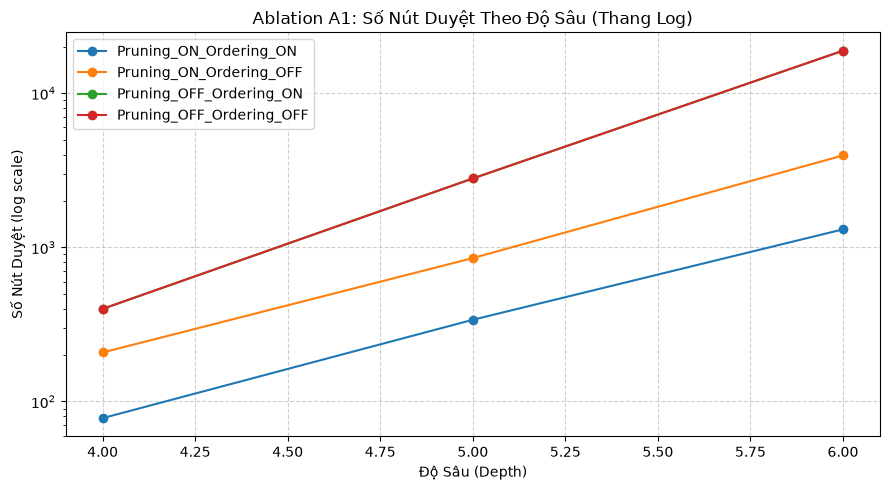

In [2]:
a1_file = TABLES_DIR / "ablation_a1_results.csv"
if a1_file.exists():
    df_a1 = pd.read_csv(a1_file)
    display(df_a1)
    
    # Vẽ biểu đồ so sánh số nút duyệt theo độ sâu
    plt.figure(figsize=(9, 5))
    for cfg in df_a1["Config"].unique():
        sub = df_a1[df_a1["Config"] == cfg]
        plt.plot(sub["Depth"], sub["Nodes"], marker="o", label=cfg)
    plt.yscale("log")
    plt.title("Ablation A1: Số Nút Duyệt Theo Độ Sâu (Thang Log)")
    plt.xlabel("Độ Sâu (Depth)")
    plt.ylabel("Số Nút Duyệt (log scale)")
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "ablation_a1_nodes.png", dpi=300)
    plt.show()
else:
    print("Chưa có dữ liệu ablation_a1_results.csv. Hãy chạy: python scripts/run_ablation.py --a1")

## 2. Phân Tích Ablation A2: Quy Mô MCTS (Simulations) vs Alpha-Beta (RQ1)
Khảo sát mối quan hệ giữa số lượng mô phỏng MCTS (100 - 5.000) và điểm số đối đầu với Alpha-Beta depth 4.

,MCTS_Simulations,Opponent,Games,MCTS_Wins,Draws,AlphaBeta_Wins,Score,Score_CI_Low,Score_CI_High,WinRate,Mean_Time_ms,p95_Time_ms
0,100,alphabeta_depth4,100,5,3,92,0.065,0.025,0.115,0.05,3.022,4.616
1,500,alphabeta_depth4,100,29,3,68,0.305,0.220,0.395,0.29,15.886,28.197
2,1000,alphabeta_depth4,100,42,0,58,0.420,0.320,0.520,0.42,35.894,71.396
3,2000,alphabeta_depth4,100,51,6,43,0.540,0.445,0.635,0.51,61.195,118.431
4,5000,alphabeta_depth4,100,57,3,40,0.585,0.490,0.680,0.57,155.397,287.937


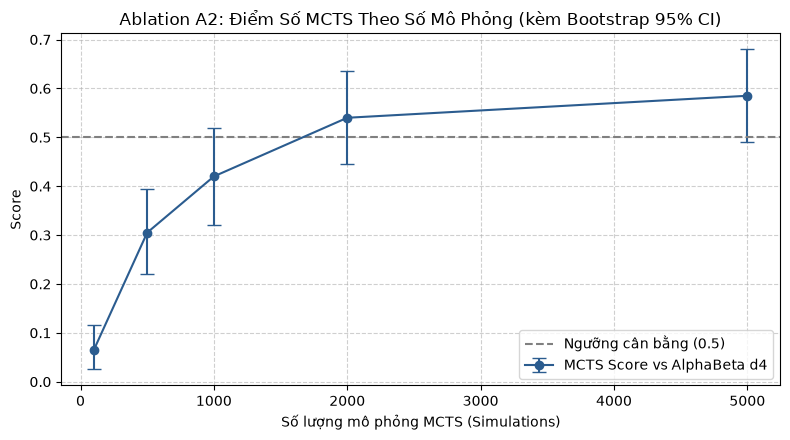

In [3]:
a2_file = TABLES_DIR / "ablation_a2_results.csv"
if a2_file.exists():
    df_a2 = pd.read_csv(a2_file)
    display(df_a2)
    
    plt.figure(figsize=(8, 4.5))
    plt.errorbar(
        df_a2["MCTS_Simulations"],
        df_a2["Score"],
        yerr=[df_a2["Score"] - df_a2["Score_CI_Low"], df_a2["Score_CI_High"] - df_a2["Score"]],
        fmt="-o", capsize=5, color="#2b5c8f", label="MCTS Score vs AlphaBeta d4"
    )
    plt.axhline(0.5, color="gray", linestyle="--", label="Ngưỡng cân bằng (0.5)")
    plt.title("Ablation A2: Điểm Số MCTS Theo Số Mô Phỏng (kèm Bootstrap 95% CI)")
    plt.xlabel("Số lượng mô phỏng MCTS (Simulations)")
    plt.ylabel("Score")
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "ablation_a2_scaling.png", dpi=300)
    plt.show()
else:
    print("Chưa có dữ liệu ablation_a2_results.csv. Hãy chạy: python scripts/run_ablation.py --a2")

## 3. Tổng Hợp Ma Trận Kết Quả Đối Đầu Toàn Bộ Các Cặp Tác Tử (Round-Robin)
Hiển thị bảng tổng kết từ giải đấu round-robin và vẽ biểu đồ thanh so sánh sức mạnh tổng thể.

In [4]:
tournament_summary = TABLES_DIR / "round_robin_default_summary.csv"
if tournament_summary.exists():
    df_t = pd.read_csv(tournament_summary)
    display(df_t)
else:
    print("Chưa có tệp giải đấu mặc định. Hãy chạy: python scripts/run_tournament.py")

,Pair,Agent_A,Agent_B,Time_Limit_s,Games,A_Wins,Draws,B_Wins,A_Score,A_Score_CI_Low,A_Score_CI_High,A_WinRate,A_Mean_Time_ms,A_p95_Time_ms,B_Mean_Time_ms,B_p95_Time_ms
0,random_vs_heuristic,random,heuristic,custom,200,1,0,199,0.0050,0.0000,0.0150,0.005,0.002,0.004,0.058,0.111
1,random_vs_alphabeta,random,alphabeta,custom,200,0,0,200,0.0000,0.0000,0.0000,0.000,0.004,0.007,12.472,29.381
2,random_vs_mcts,random,mcts,custom,200,0,0,200,0.0000,0.0000,0.0000,0.000,0.003,0.004,37.105,54.366
3,heuristic_vs_alphabeta,heuristic,alphabeta,custom,200,25,17,158,0.1675,0.1225,0.2175,0.125,0.049,0.083,8.425,23.726
4,heuristic_vs_mcts,heuristic,mcts,custom,200,41,11,148,0.2325,0.1775,0.2901,0.205,0.052,0.089,29.356,49.266
5,alphabeta_vs_mcts,alphabeta,mcts,custom,200,135,4,61,0.6850,0.6200,0.7475,0.675,8.485,23.373,30.767,50.296


## 4. So sánh sức mạnh các tác tử
So sánh điểm số của từng cặp trong giải đấu mặc định. Điểm số của Agent A tính bằng (số thắng + 0.5 × số hòa) / tổng số ván.

,Pair,Games,A_Wins,Draws,B_Wins,A_Score
0,random_vs_heuristic,200,1,0,199,0.0050
1,random_vs_alphabeta,200,0,0,200,0.0000
2,random_vs_mcts,200,0,0,200,0.0000
3,heuristic_vs_alphabeta,200,25,17,158,0.1675
4,heuristic_vs_mcts,200,41,11,148,0.2325
5,alphabeta_vs_mcts,200,135,4,61,0.6850


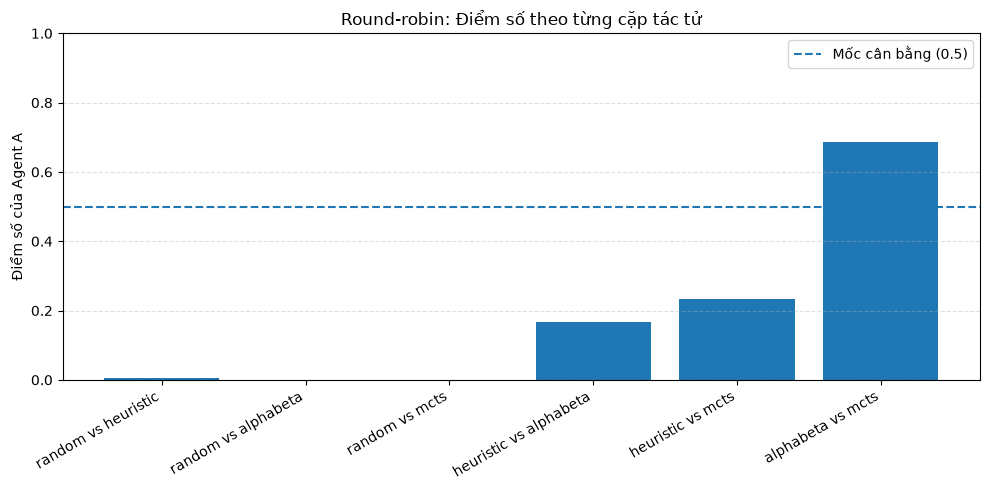

In [5]:
summary_file = TABLES_DIR / "round_robin_default_summary.csv"
df_t = pd.read_csv(summary_file)
display(df_t[["Pair", "Games", "A_Wins", "Draws", "B_Wins", "A_Score"]])

plt.figure(figsize=(10, 5))
labels = df_t["Pair"].str.replace("_vs_", " vs ", regex=False)
plt.bar(labels, df_t["A_Score"])
plt.axhline(0.5, linestyle="--", label="Mốc cân bằng (0.5)")
plt.ylim(0, 1)
plt.ylabel("Điểm số của Agent A")
plt.title("Round-robin: Điểm số theo từng cặp tác tử")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "round_robin_scores.png", dpi=300)
plt.show()

## 5. Phân tích timed tournament
So sánh kết quả thăm dò Alpha-Beta và MCTS ở giới hạn thời gian 100 ms và 300 ms. Mỗi mức có 20 ván; không nên xem khác biệt này là kết luận thống kê chắc chắn.

,Pair,Games,A_Wins,Draws,B_Wins,A_Score,A_Mean_Time_ms,B_Mean_Time_ms
0,alphabeta_vs_mcts_100ms,20,12,0,8,0.60,69.486,99.934
1,alphabeta_vs_mcts_300ms,20,9,0,11,0.45,193.386,295.109


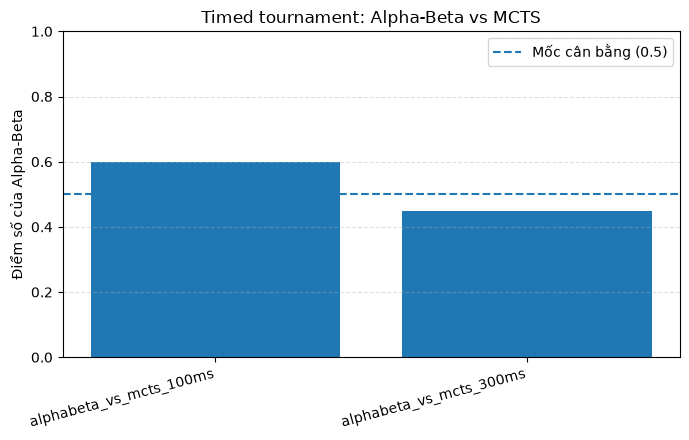

In [6]:
timed_file = TABLES_DIR / "round_robin_timed_quick_summary.csv"
if timed_file.exists():
    df_timed = pd.read_csv(timed_file)
    display(df_timed[["Pair", "Games", "A_Wins", "Draws", "B_Wins", "A_Score", "A_Mean_Time_ms", "B_Mean_Time_ms"]])

    plt.figure(figsize=(7, 4.5))
    plt.bar(df_timed["Pair"], df_timed["A_Score"])
    plt.axhline(0.5, linestyle="--", label="Mốc cân bằng (0.5)")
    plt.ylim(0, 1)
    plt.ylabel("Điểm số của Alpha-Beta")
    plt.title("Timed tournament: Alpha-Beta vs MCTS")
    plt.xticks(rotation=15, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.4)
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "timed_tournament_scores.png", dpi=300)
    plt.show()
else:
    print("Chưa tìm thấy round_robin_timed_quick_summary.csv")

## 6. Nhận xét và kết luận
- Ablation A1 và A2 được phân tích từ các bảng kết quả thực nghiệm.
- Round-robin mặc định gồm 6 cặp tác tử, mỗi cặp 200 ván.
- Alpha-Beta đạt 135 thắng, 4 hòa và 61 thua khi đấu với MCTS trong cấu hình mặc định.
- Trong timed tournament thăm dò, Alpha-Beta thắng 12/20 ván ở mức 100 ms và 9/20 ván ở mức 300 ms.
- Do số ván timed tournament còn ít, cần chạy nhiều ván hơn trước khi kết luận về ảnh hưởng của giới hạn thời gian.